In [1]:

#importing pandas library which contains the functions related to the database manipulation activities
import pandas as pd

In [2]:
#dataset is is loaded from "Dataset"  a folder placed alongside this .ipynb file"
dataset=pd.read_csv("Dataset/50_Startups.csv")

In [3]:
# to Check the values of the dataset
dataset

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94
5,131876.90,99814.71,362861.36,New York,156991.12
6,134615.46,147198.87,127716.82,California,156122.51
7,130298.13,145530.06,323876.68,Florida,155752.60
8,120542.52,148718.95,311613.29,New York,152211.77
9,123334.88,108679.17,304981.62,California,149759.96


In [4]:
#for creating the one hot encoding which is a process of quantizing the string into numerical value to enable it for the usage in ML system and "drop_first= True " to drop the First column of one hot encoding to minimize the column
dataset=pd.get_dummies(dataset,drop_first=True)

In [5]:
# to Check the values of the dataset with one hot encoding except the first column of it
dataset

,R&D Spend,Administration,Marketing Spend,Profit,State_Florida,State_New York
0,165349.20,136897.80,471784.10,192261.83,False,True
1,162597.70,151377.59,443898.53,191792.06,False,False
2,153441.51,101145.55,407934.54,191050.39,True,False
3,144372.41,118671.85,383199.62,182901.99,False,True
4,142107.34,91391.77,366168.42,166187.94,True,False
5,131876.90,99814.71,362861.36,156991.12,False,True
6,134615.46,147198.87,127716.82,156122.51,False,False
7,130298.13,145530.06,323876.68,155752.60,True,False
8,120542.52,148718.95,311613.29,152211.77,False,True
9,123334.88,108679.17,304981.62,149759.96,False,False


In [6]:
dataset.columns

Index(['R&D Spend', 'Administration', 'Marketing Spend', 'Profit',
       'State_Florida', 'State_New York'],
      dtype='object')

In [7]:
#creating the independent by splitting from original dataset serves as input 
independent=dataset[['R&D Spend', 'Administration', 'Marketing Spend','State_Florida', 'State_New York']]

In [8]:
# to display independent table
independent

,R&D Spend,Administration,Marketing Spend,State_Florida,State_New York
0,165349.20,136897.80,471784.10,False,True
1,162597.70,151377.59,443898.53,False,False
2,153441.51,101145.55,407934.54,True,False
3,144372.41,118671.85,383199.62,False,True
4,142107.34,91391.77,366168.42,True,False
5,131876.90,99814.71,362861.36,False,True
6,134615.46,147198.87,127716.82,False,False
7,130298.13,145530.06,323876.68,True,False
8,120542.52,148718.95,311613.29,False,True
9,123334.88,108679.17,304981.62,False,False


In [9]:
#creating the independent by splitting from original dataset serves as output which is the label 
dependent=dataset[["Profit"]]

In [10]:
#Splitting the Rows of data as a part for Training the model and and another part for Testing the model's performance using four variables 2 from dependent and 2 from independent 
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(independent, dependent, test_size=0.30,random_state=0)


In [11]:
from sklearn.ensemble import RandomForestRegressor
regressor = RandomForestRegressor()
rf_regressor_Default = regressor.fit(X_train,y_train)

C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


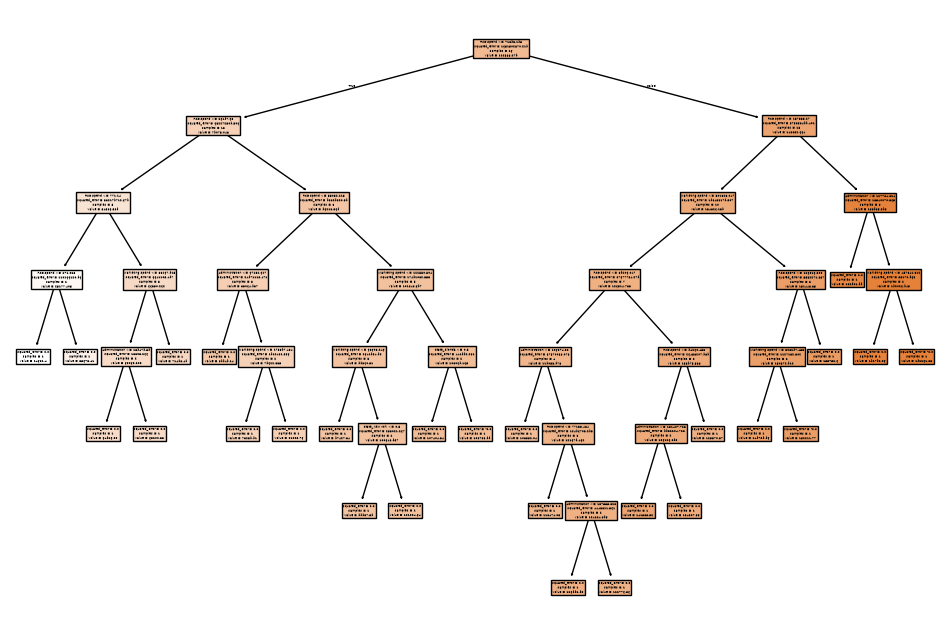

In [15]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# USE THE PARAMETERS
clf = RandomForestRegressor(n_estimators=50, random_state=42)
clf.fit(X_train, y_train)

# 2. Plot a single tree (e.g., the first tree at index 0)
plt.figure(figsize=(12, 8))
plot_tree(
    clf.estimators_[0],
    feature_names=['R&D Spend', 'Administration', 'Marketing Spend','State_Florida', 'State_New York'],
    class_names=["Profit"],
    filled=True,
)
plt.show()


Predicting with the Default Parameters without Tweaking the Parametric values

In [16]:
#Predicting function usage to predict value for the given x in test portion which was not used for training
y_pred_rf  = rf_regressor_Default.predict(X_test)
print(y_pred_rf)

[104294.2618 134776.836  136996.1096  78915.405  181958.6864 120135.9194
  71136.5635 100717.9013 115333.6827 168675.2047 100715.966   87646.9517
 118500.5339  89123.4323 129982.1112]


In [23]:
from sklearn.metrics import r2_score

#importing the function r2 a scoring system from sklearn to check the difference in the value of "predicted y" and the actual value of "labeled y" and squaring it for maximizing the difference . 

r_score_RF_Default  = (r2_score(y_test,y_pred_rf))

print("The Default RSquare Score is " +str(r_score_RF_Default))

The Default RSquare Score is 0.9325169418608336


Predicting with the Multiple Parametric Combinations without Tweaked the Parametric values and check multiple Results

In [24]:

from sklearn.metrics import r2_score


In [37]:
def describe_article(paramA, paramB, paramC):
    """
    Returns a description string for an article based on its
    size, shape, and colour.
    """
    return f"The result of the parametric combinations of Criterion:{paramA} , Estimator_Count:{paramB} , Max_features:{paramC} . are:"


def main():
    criterion_List = ["squared_error", "absolute_error", "poisson"]
    estimator_List = [10, 20 , 30 ,50 , 75 , 100]
    max_features_List = ["sqrt", "log2",.1,.2,.3,.4,.5,.6,.7,.8,.9,1]
    result_List=[]

    count = 0
    for criterionVal in criterion_List:
        for estimatorVal in estimator_List:
            for max_featuresVal in max_features_List:
                count += 1
                regressor = RandomForestRegressor(criterion = criterionVal ,n_estimators = estimatorVal , max_features = max_featuresVal)
                rf_regressor = regressor.fit(X_train,y_train)
                y_pred_dt  = rf_regressor.predict(X_test)
                r_score_RF  = (r2_score(y_test,y_pred_dt))    
                result_List.append(r_score_RF)         
                print(f"{count}. {describe_article(criterionVal, estimatorVal, max_featuresVal)} {r_score_RF} ")
                

    print(f"\nTotal combinations printed: {count}")
    print("the max value among the Result is :"+ str(result_List.index(max(result_List))+1))


if __name__ == "__main__":
        main()

C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y 

1. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:10 , Max_features:sqrt . are: 0.5171066907765559 
2. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:10 , Max_features:log2 . are: 0.8111719559058423 
3. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:10 , Max_features:0.1 . are: 0.5958690861877101 
4. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:10 , Max_features:0.2 . are: 0.22457170135051796 
5. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:10 , Max_features:0.3 . are: 0.6304608125719304 
6. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:10 , Max_features:0.4 . are: 0.7231111620198087 
7. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:10 , Max_features:0.5 . are: 0.821904836915742 
8. The result of the para

C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y 

17. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:20 , Max_features:0.3 . are: 0.7772378279149708 
18. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:20 , Max_features:0.4 . are: 0.7791819148421493 
19. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:20 , Max_features:0.5 . are: 0.7121089144121899 
20. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:20 , Max_features:0.6 . are: 0.898352663007142 
21. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:20 , Max_features:0.7 . are: 0.900628929405574 
22. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:20 , Max_features:0.8 . are: 0.9253404790599282 


C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y 

...

C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


213. The result of the parametric combinations of Criterion:poisson , Estimator_Count:100 , Max_features:0.7 . are: 0.8737511291395992 
214. The result of the parametric combinations of Criterion:poisson , Estimator_Count:100 , Max_features:0.8 . are: 0.8974246121898786 


C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


215. The result of the parametric combinations of Criterion:poisson , Estimator_Count:100 , Max_features:0.9 . are: 0.9104472009385172 
216. The result of the parametric combinations of Criterion:poisson , Estimator_Count:100 , Max_features:1 . are: 0.5297797003846383 

Total combinations printed: 216
the max value among the Result is :143


C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Considering the 12 iterative outputs :
iteration1.82. The result of the parametric combinations of Criterion:absolute_error , Estimator_Count:10 , Max_features:0.8 . are: 0.9476600810484499 
iteration2.20. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:20 , Max_features:0.6 . are: 0.9420922684426675 
iteration3.119. The result of the parametric combinations of Criterion:absolute_error , Estimator_Count:50 , Max_features:0.9 . are: 0.9443044104638088 
iteration4.82. The result of the parametric combinations of Criterion:absolute_error , Estimator_Count:10 , Max_features:0.8 . are: 0.9471696753257781 
iteration5.10. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:10 , Max_features:0.8 . are: 0.9462325019015558 
iteration6.82. The result of the parametric combinations of Criterion:absolute_error , Estimator_Count:10 , Max_features:0.8 . are: 0.9447977915554859 
iteration7.118. The result of the parametric combinations of Criterion:absolute_error , Estimator_Count:50 , Max_features:0.8 . are: 0.9419062291666648 
iteration8.83. The result of the parametric combinations of Criterion:absolute_error , Estimator_Count:10 , Max_features:0.9 . are: 0.9484741424882649 
iteration9.155. The result of the parametric combinations of Criterion:poisson , Estimator_Count:10 , Max_features:0.9 . are: 0.951874199973245 
iteration10.166. The result of the parametric combinations of Criterion:poisson , Estimator_Count:20 , Max_features:0.8 . are: 0.9541138514734638 
iteration11.47. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:50 , Max_features:0.9 . are: 0.9460007487510352 
iteration12.143. The result of the parametric combinations of Criterion:absolute_error , Estimator_Count:100 , Max_features:0.9 . are: 0.9433516207278997 

From the observation in multiple iterative runs the best RSquare Score is obtained in the iteration10 :
166. The result of the parametric combinations of Criterion:poisson , Estimator_Count:20 , Max_features:0.8 . are: 0.9541138514734638 

let us consider only the combinations in the 12 iterations and do the runs to obtain the best scored model with a condition on the score



Considering the float range of parameter for max_features: from 0.6 to 0.9 and n_estimators : of 10,20,50,100 then we will minimize Iteration


In [41]:
def describe_article(paramA, paramB, paramC):
    """
    Returns a description string for an article based on its
    size, shape, and colour.
    """
    return f"The result of the parametric combinations of Criterion:{paramA} , Estimator_Count:{paramB} , Max_features:{paramC} . are:"


def main():
    criterion_List = ["squared_error", "absolute_error", "poisson"]
    estimator_List = [10, 20 ,50 , 100]
    max_features_List = [.6,.7,.8,.9]
    result_List=[]
    rf_regressor_List = []

    count = 0
    for criterionVal in criterion_List:
        for estimatorVal in estimator_List:
            for max_featuresVal in max_features_List:
                count += 1
                regressor = RandomForestRegressor(criterion = criterionVal ,n_estimators = estimatorVal , max_features = max_featuresVal)
                rf_regressor = regressor.fit(X_train,y_train)
                y_pred_dt  = rf_regressor.predict(X_test)
                r_score_RF  = (r2_score(y_test,y_pred_dt))    
                result_List.append(r_score_RF)   
                rf_regressor_List.append(rf_regressor)
                print(f"{count}. {describe_article(criterionVal, estimatorVal, max_featuresVal)} {r_score_RF} ")
                

    print(f"\nTotal combinations printed: {count}")
    print("the max value among the Result is :"+ str(result_List.index(max(result_List))+1))
    
    best_Fited_Regressor = rf_regressor_List[int(result_List.index(max(result_List)))] 
    return max(result_List) , best_Fited_Regressor


if __name__ == "__main__":
    #getting the Best Fit from the List
    best_Regressor = main()

RSquareScore , Model = best_Regressor
print(RSquareScore , Model) 



C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y 

1. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:10 , Max_features:0.6 . are: 0.9141903451204532 
2. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:10 , Max_features:0.7 . are: 0.8659672515421866 
3. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:10 , Max_features:0.8 . are: 0.8920286614564704 
4. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:10 , Max_features:0.9 . are: 0.9597240918539941 
5. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:20 , Max_features:0.6 . are: 0.8848799855796751 
6. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:20 , Max_features:0.7 . are: 0.9035759983585014 
7. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:20 , Max_features:0.8 . are: 0.9171393889800197 
8. The result of the parame

C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y 

11. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:50 , Max_features:0.8 . are: 0.9261404266750666 
12. The result of the parametric combinations of Criterion:squared_error , Estimator_Count:50 , Max_features:0.9 . are: 0.8950381701388752 


C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


...

C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y 

45. The result of the parametric combinations of Criterion:poisson , Estimator_Count:100 , Max_features:0.6 . are: 0.8623634580484125 
46. The result of the parametric combinations of Criterion:poisson , Estimator_Count:100 , Max_features:0.7 . are: 0.8967329927332053 


C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


47. The result of the parametric combinations of Criterion:poisson , Estimator_Count:100 , Max_features:0.8 . are: 0.9167727382083173 
48. The result of the parametric combinations of Criterion:poisson , Estimator_Count:100 , Max_features:0.9 . are: 0.9309533600987212 

Total combinations printed: 48
the max value among the Result is :4
0.9597240918539941 RandomForestRegressor(max_features=0.9, n_estimators=10)


C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


In [ ]:

# Importing the pickling function to pickle the best model which is using linear as Kernel Parameter.
import pickle
if RSquareScore > 0.9541: # checks the best value obtained in the 12 iterations 
    # Assigning the variable for filename
    filename="Saved_Model/finalized_best_Model.sav"
    # dump function of pickle to write the pickled structure as a file from the variable used for file name
    pickle.dump(Model,open(filename,'wb'))

Deployment Section

In [46]:
# load function of pickle to read the pickled structure from the already saved "finalized_model_Mul_linear.sav"
loaded_model=pickle.load(open("Saved_Model/finalized_best_Model.sav",'rb'))
#Predicting the result for the input "1234,345,4565,1,0" the order of items to be same as the training
result=loaded_model.predict([[1234,345,4565,1,0]])
print(f"The Result is {result[0] : .4f}")


The Result is  53889.2790


C:\Users\haris\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
